# 3 Body Problem
The 3 body problem, a subset of the N-body problem, is a system of 3 particles that interact with each other through gravitational forces and the goal of the problem is to predict the motions of the individual particles. The N-body systems are chaotic for $N>2$, which means that the paths of the particles a highly dependent on the intial conditions of the system, as well as the numerical methods implemented to simulate the evolution of it. The goal of this project is to implement different numerical methods to simulate systems and compare their effectiveness. I predict that systems that conserve energy such as velocity verlet and leapfrog will perform better than counterparts of similar order, and methods like Runge-Kutta-4, will perform better when considering larger step sizes due to better error rates.

The project will also demonstrate an example of stable 3 body systems and how it becomes unstable (chaotic) when the parameters are varied, and finally we will attempt to simulate the precession of mercury due to the influence of venus, this was the original goal of the project.

![alt text](img/3-body.png "3 body diagram")

In the above figure $[1]$, we can see the different forces experienced by each of the particles in the system, each force can be given by
$$
 F_{ba} = -\frac{Gm_am_b\vec{r_{ba}}}{|\vec{r_{ba}}|^3}
$$
where G is the gravitational constant, $m_a$ and $m_b$ are the masses, and $r_{ab}$ is the vector connecting particles $a$ and $b$, and can be written as $\vec{r_{ba}} = \vec{r_a} - \vec{r_b}$.

The force experienced by particle $a$ would then be
$$
 F_a = -\frac{Gm_am_b\vec{r_{ba}}}{|\vec{r_{ba}}|^3} -\frac{Gm_am_c\vec{r_{ca}}}{|\vec{r_{ca}}|^3}
$$
and the acceleration would be,
$$
 a_a = -\frac{Gm_b\vec{r_{ba}}}{|\vec{r_{ba}}|^3} -\frac{Gm_c\vec{r_{ca}}}{|\vec{r_{ca}}|^3}
$$

We can similarly define equations for particles b and c,

$$
 a_b = -\frac{Gm_a\vec{r_{ab}}}{|\vec{r_{ab}}|^3} -\frac{Gm_c\vec{r_{cb}}}{|\vec{r_{cb}}|^3}
$$
$$
 a_c = -\frac{Gm_a\vec{r_{ac}}}{|\vec{r_{ac}}|^3} -\frac{Gm_b\vec{r_{bc}}}{|\vec{r_{bc}}|^3}
$$



We also rewrite the gravitational equations, and split them into 2 first order equations. So the gravitational equation
$$
{\mathrm{d}^2 x\over\mathrm{d} t^2} = -GM \frac{r}{|r|^3}\,,
$$
can be written as
$$
\frac{\mathrm{d} v}{\mathrm{d} t} = -GM \frac{r}{ |r|^3}\,, \qquad
\frac{\mathrm{d} x}{\mathrm{d} t} = {v}\,
$$

First we will write down the function

In [6]:
import numpy as np
from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import animation
from IPython.display import HTML

In [8]:
def func(m,r,v):
    """
    returns dv/dt and dr/dt
    """
    m_1, m_2, m_3 = m[0],m[1],m[2]
    r_1, r_2, r_3 = r[0],r[1],r[2]

    a_1 = - G*(m_2)*(r_1-r_2)/np.sqrt(np.sum((r_1 - r_2)**2)**3) - G*(m_3)*(r_1-r_3)/np.sqrt(np.sum((r_1-r_3)**2)**3)
    a_2 = - G*(m_1)*(r_2-r_1)/np.sqrt(np.sum((r_2 - r_1)**2)**3) - G*(m_3)*(r_2-r_3)/np.sqrt(np.sum((r_2-r_3)**2)**3)
    a_3 = - G*(m_1)*(r_3-r_1)/np.sqrt(np.sum((r_3 - r_1)**2)**3) - G*(m_2)*(r_3-r_2)/np.sqrt(np.sum((r_3-r_2)**2)**3)

    return np.array([a_1, a_2, a_3]), v

Next we will write down 3 methods for solving the differential equations:
1. Eulers method
2. Velocity Verlet
3. Runge-Kutta-4

We write down helper functions for intitialising arrays and plotting first

In [9]:
def init(r0,v0,steps):
    
    r1 = np.array([[0.,0.,0.] for i in range(steps)])
    v1 = np.array([[0.,0.,0.] for i in range(steps)])

    r2 = np.array([[0.,0.,0.] for j in range(steps)])
    v2 = np.array([[0.,0.,0.] for j in range(steps)])

    r3 = np.array([[0.,0.,0.] for k in range(steps)])
    v3 = np.array([[0.,0.,0.] for k in range(steps)])
    
    # initial conditions
    r1[0], r2[0], r3[0] = r0[0], r0[1], r0[2]
    v1[0], v2[0], v3[0] = v0[0], v0[1], v0[2]
    
    return r1,r2,r3, v1,v2,v3

def plot_path(r1,r2,r3):
    
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(projection='3d')
    plt.gca().patch.set_facecolor('black')

    plt.plot([i[0] for i in r1], [j[1] for j in r1], [k[2] for k in r1] , '^', color='red', lw = 0.05, markersize = 0.01, alpha=0.5)
    plt.plot([i[0] for i in r2], [j[1] for j in r2], [k[2] for k in r2] , '^', color='white', lw = 0.05, markersize = 0.01, alpha=0.5)
    plt.plot([i[0] for i in r3], [j[1] for j in r3], [k[2] for k in r3] , '^', color='blue', lw = 0.05, markersize = 0.01, alpha=0.5)

    plt.axis('on')

    ax.set_xticks([]), ax.set_yticks([]), ax.set_zticks([])
    plt.show()
    plt.close()    
    
def anim_path(r1,r2,r3,limits=1,elev = 30,azim = 45,step = 100):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    path_history = {
        'r1': [],
        'r2': [],
        'r3': []
    }

    # Define the function to animate
    def update(frame):
        ax.clear()
        frame *= step
        # Generate data for the 3D plot

        for key, path in path_history.items():
            if path:
                path_array = np.array(path)
                ax.plot(path_array[:, 0], path_array[:, 1], path_array[:, 2], alpha=0.5)
        # Update positions
        for key, value in {'r1': r1, 'r2': r2, 'r3': r3}.items():
            ax.plot(value[frame, 0], value[frame, 1], value[frame, 2], label=key)
            path_history[key].append(value[frame])

        x = np.array([r1[frame,0],r2[frame,0],r3[frame,0]])
        y = np.array([r1[frame,1],r2[frame,1],r3[frame,1]])
        z = np.array([r1[frame,2],r2[frame,2],r3[frame,2]])
        # Plot the data
        ax.scatter(x, y, z)
        # Set labels and title
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')
        ax.set_title('3D Plot Animation')
        ax.set_xlim(-limits, limits)  
        ax.set_ylim(-limits, limits)    
        ax.set_zlim(-limits, limits)  
        ax.view_init(elev=elev, azim=azim)

    # Create the animation
    ani = animation.FuncAnimation(fig, update, frames=(r1.shape[0]+1)//step, interval=40)
    
    return ani

In [10]:
def euler(f, r0, v0, m, t0, tf, h, plot=False):
    
    steps = int((tf-t0)//h)
    r1,r2,r3,v1,v2,v3 = init(r0,v0,steps)
    
    print('r:{}, v:{}'.format(r1.shape,v1.shape))
    
    for i in range(steps-1):
        
        # calculate derivatives
        r = np.array([r1[i],r2[i],r3[i]])
        v = np.array([v1[i],v2[i],v3[i]])
        dv,dr= f(m,r,v)

        v1[i + 1] = v1[i] + dv[0] * h
        v2[i + 1] = v2[i] + dv[1] * h
        v3[i + 1] = v3[i] + dv[2] * h

        r1[i + 1] = r1[i] + dr[0] * h
        r2[i + 1] = r2[i] + dr[1] * h
        r3[i + 1] = r3[i] + dr[2] * h
    
    if plot:
        plot_path(r1,r2,r3)

    return r1,r2,r3

In [11]:
def verlet(f, r0, v0, m, t0, tf, h, plot=False):
    
    steps = int((tf-t0)//h)
    r1,r2,r3,v1,v2,v3 = init(r0,v0,steps)
    
    print('r:{}, v:{}'.format(r1.shape,v1.shape))
    
    #mid point calculation
    r = np.array([r1[0],r2[0],r3[0]])
    dv,dr = f(m,r,v0)
    v_mid = np.array([v1[0] + dv[0] * h * 0.5, v2[0] + dv[1] * h * 0.5,v3[0] + dv[2] * h * 0.5])
    
    for i in range(steps-1):
        
        # calculate derivatives
        r1[i + 1] = r1[i] + v_mid[0] * h
        r2[i + 1] = r2[i] + v_mid[1] * h
        r3[i + 1] = r3[i] + v_mid[2] * h
        
        r = np.array([r1[i+1],r2[i+1],r3[i+1]])

        vk, rk = f(m,r,v_mid)
        vk = vk * h
        
        v1[i + 1] = v_mid[0] + vk[0]/2
        v2[i + 1] = v_mid[1] + vk[1]/2
        v3[i + 1] = v_mid[2] + vk[2]/2
        
        v_mid += vk
    
    if plot:
        plot_path(r1,r2,r3)
    
    return r1,r2,r3

In [12]:
def rk4(f, r0, v0, m, t0, tf, h, plot=False):
    
    steps = int((tf-t0)//h)
    r1,r2,r3,v1,v2,v3 = init(r0,v0,steps)
    
    print('r:{}, v:{}'.format(r1.shape,v1.shape))
    
    for i in range(steps-1):
        
        # calculate derivatives
        r = np.array([r1[i],r2[i],r3[i]])
        v = np.array([v1[i],v2[i],v3[i]])
        
        vk1, rk1 = h* np.array(f(m,r,v))
        vk2, rk2 = h* np.array(f(m,r + rk1/2,v + vk1/2))
        vk3, rk3 = h* np.array(f(m,r + rk2/2,v + vk2/2))
        vk4, rk4 = h* np.array(f(m,r + rk3,v + vk3))  
         

        v1[i + 1] = v1[i] + (vk1[0] + 2*vk2[0] + 2*vk3[0] + vk4[0])/6
        v2[i + 1] = v2[i] + (vk1[1] + 2*vk2[1] + 2*vk3[1] + vk4[1])/6
        v3[i + 1] = v3[i] + (vk1[2] + 2*vk2[2] + 2*vk3[2] + vk4[2])/6
        
        r1[i + 1] = r1[i] + (rk1[0] + 2*rk2[0] + 2*rk3[0] + rk4[0])/6
        r2[i + 1] = r2[i] + (rk1[1] + 2*rk2[1] + 2*rk3[1] + rk4[1])/6
        r3[i + 1] = r3[i] + (rk1[2] + 2*rk2[2] + 2*rk3[2] + rk4[2])/6
    
    if plot:
        plot_path(r1,r2,r3)

    return r1,r2,r3

With the functions for plotting and solving the evolution of the system ready, we will now go through some examples of systems, chaotic systems and a stable system.

First we have a chaotic:

r:(11999, 3), v:(11999, 3)


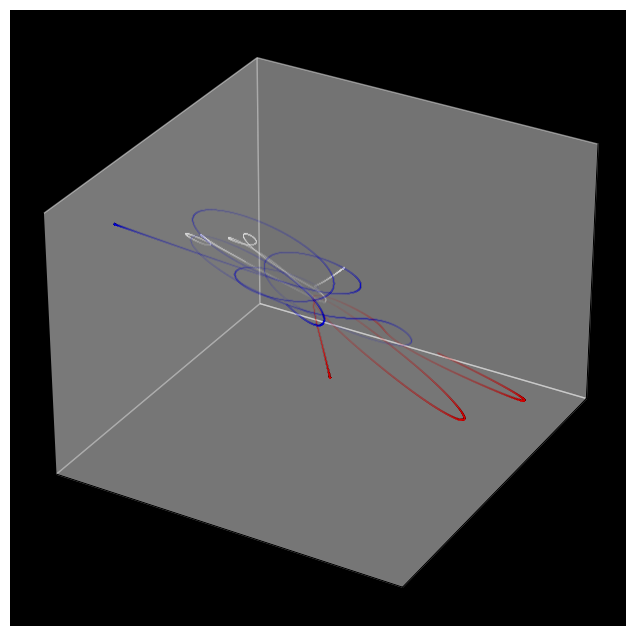

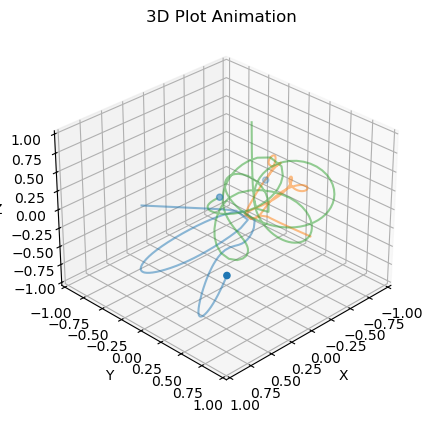

In [74]:
G = 1
m0 = np.array([0.3,0.5,0.1]) #kg G=1
r0 = np.array([[1,  0  ,0.6  ],
               [0 , 1  ,0.2  ],
               [-0.31 , 0  ,1 ]])

v0 = np.array([[0 , 0, 0],
               [0 , 0, 0],
               [0 , 0, 0]])
t0 = 0
tf = 12
h = 0.001
r1,r2,r3 = rk4(func,r0,v0,m0,t0,tf,h,plot=True)

path1 = r2

HTML(anim_path(r1,r2,r3,limits=1,step = 50).to_html5_video())

If we change initial position by a small amount lets say particle 2 position from $r_2 = (0 , 1  ,0.2)$ to $r_2 = (0 , 1  ,0.201)$, we see a deviation in the path of the particles. This is a difference of 0.5% in the z position.

r:(11999, 3), v:(11999, 3)


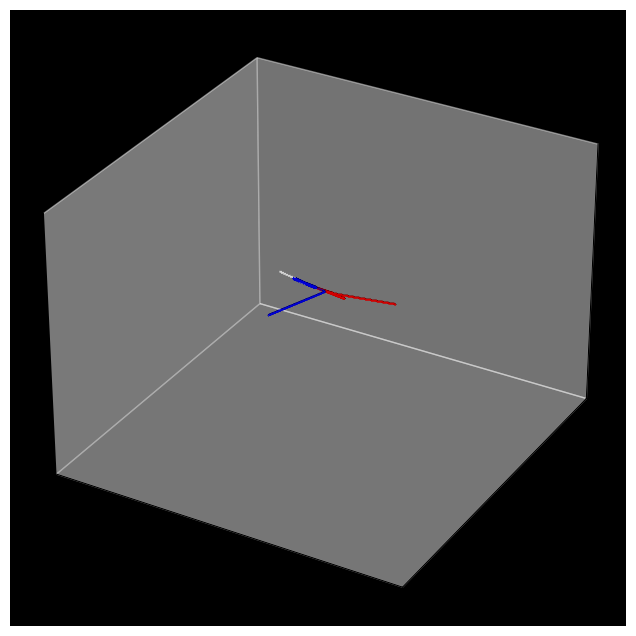

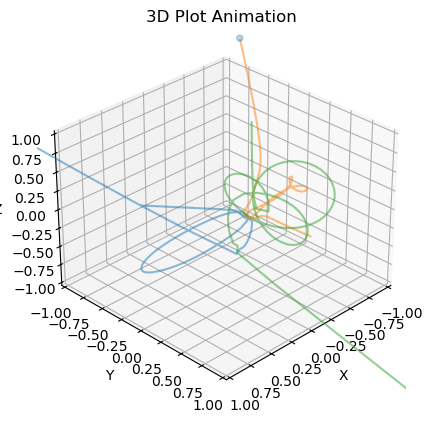

In [75]:
G = 1
m0 = np.array([0.3,0.5,0.1]) #kg G=1
r0 = np.array([[1,  0  ,0.6  ],
               [0 , 1  ,0.201  ],
               [-0.31 , 0  ,1 ]])

v0 = np.array([[0 , 0, 0],
               [0 , 0, 0],
               [0 , 0, 0]])
t0 = 0
tf = 12
h = 0.001
r1,r2,r3 = rk4(func,r0,v0,m0,t0,tf,h,plot=True)

path2 = r2

HTML(anim_path(r1,r2,r3,limits=1,step = 50).to_html5_video())

Lets visualise the difference in the path of the particle 2 upon the change mentioned above, initially the particle had a similar path but over time it diverged away, which is as expected from chaos theory. The system is very sensitive to small changes in the initial conditions, it also varies with the step size used in the solver routine.

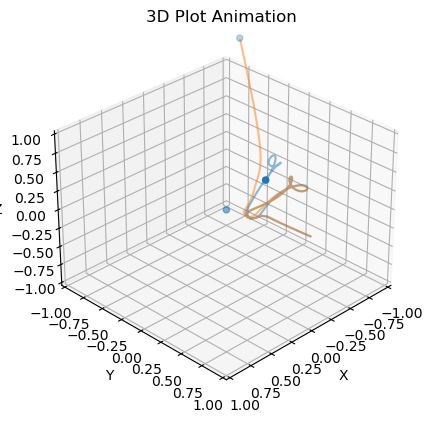

In [76]:
path3 = np.zeros_like(path1)

HTML(anim_path(path1,path2,path3,limits=1,step = 50).to_html5_video())

Let us see the same system with a different step size

r:(1199, 3), v:(1199, 3)


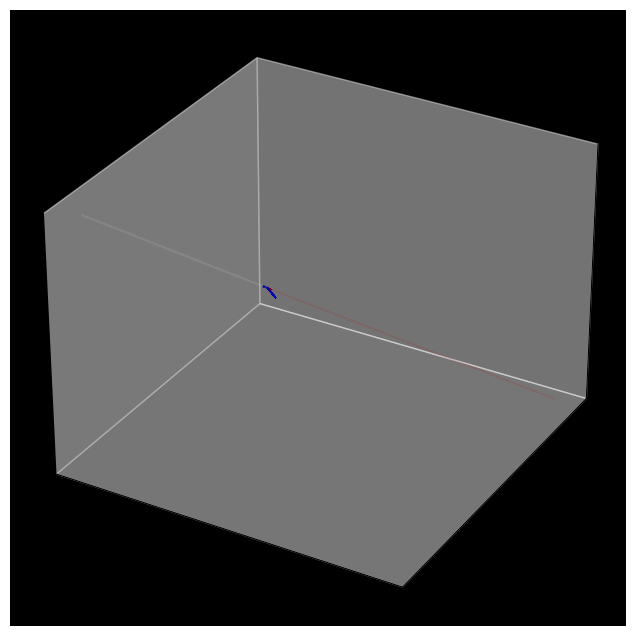

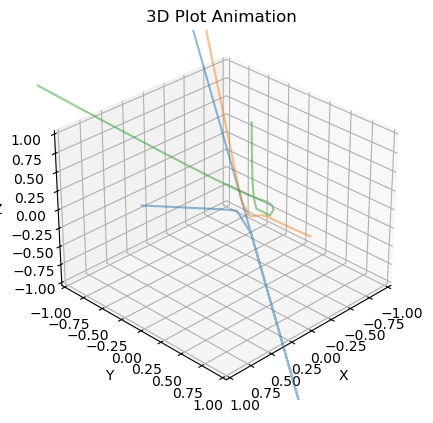

In [79]:
G = 1
m0 = np.array([0.3,0.5,0.1]) #kg G=1
r0 = np.array([[1,  0  ,0.6  ],
               [0 , 1  ,0.2  ],
               [-0.31 , 0  ,1 ]])

v0 = np.array([[0 , 0, 0],
               [0 , 0, 0],
               [0 , 0, 0]])
t0 = 0
tf = 12
h = 0.01 # step size changed to 0.01 from 0.001
r1,r2,r3 = rk4(func,r0,v0,m0,t0,tf,h,plot=True)

path1 = r2

HTML(anim_path(r1,r2,r3,limits=1,step = 5).to_html5_video())

Now let us look at a stable solution that has been discovered for the 3 body problem, It forms a 8-shaped figure $[3]$, we also compare the different implementations we have.

First we look at Velocity Verlet,

r:(1199, 3), v:(1199, 3)


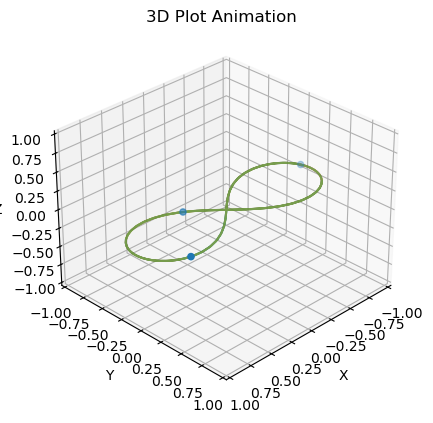

In [32]:
G = 1
m0 = np.array([1,1,1]) #kg G=1
r0 = np.array([[0.97000436,  -0.24308753  ,0  ],
               [0  ,0 ,0  ],
               [-0.97000436 , 0.24308753  ,0  ]])

v0 = np.array([[0.93240737/2 , 0.86473146/2, 0],
               [-0.93240737 , - 0.86473146, 0],
               [0.93240737/2 , 0.86473146/2, 0],])
t0 = 0
tf = 12
h = 0.01
r1,r2,r3 = verlet(func,r0,v0,m0,t0,tf,h,plot=False)

HTML(anim_path(r1,r2,r3,step = 10).to_html5_video())

Next we look at the Euler method,

r:(1199, 3), v:(1199, 3)


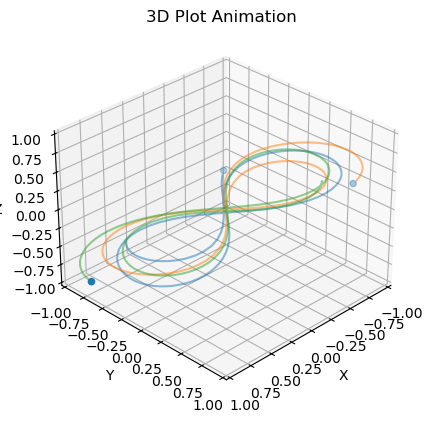

In [33]:
r1,r2,r3 = euler(func,r0,v0,m0,t0,tf,h,plot=False)

HTML(anim_path(r1,r2,r3,step = 10).to_html5_video())

And finally we look at RK4,

r:(1199, 3), v:(1199, 3)


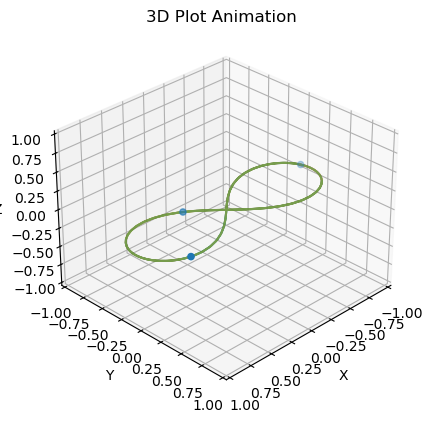

In [36]:
r1,r2,r3 = rk4(func,r0,v0,m0,t0,tf,h,plot=False)

HTML(anim_path(r1,r2,r3,step = 10).to_html5_video())

Another stable 3 body orbit that was discovered in the paper $[4]$, among many others.

r:(79999, 3), v:(79999, 3)


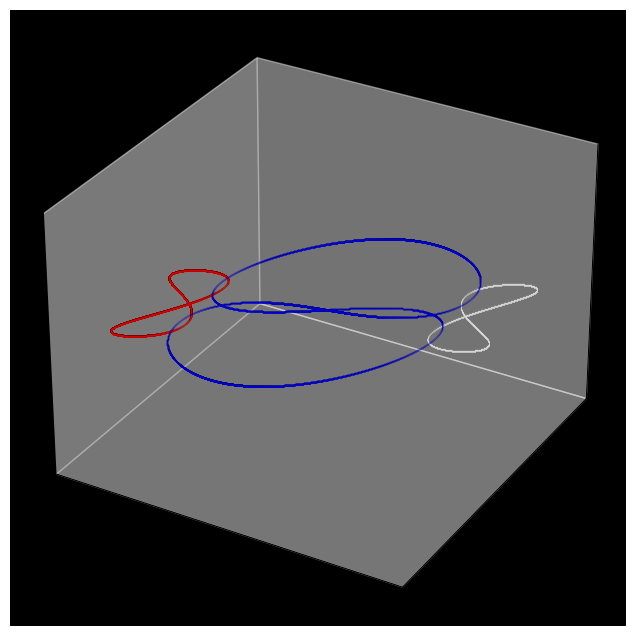

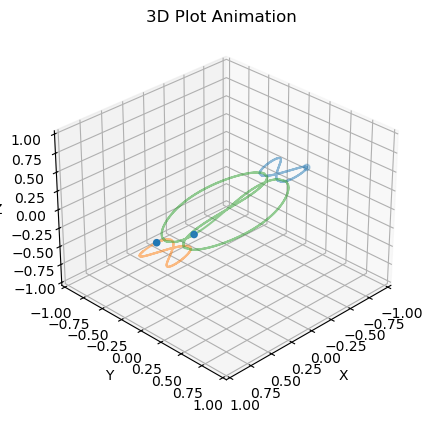

In [25]:
G = 1
m0 = np.array([1.0,1.0,0.5]) #kg

r0 = np.array([[-1,0  ,0  ],
               [1  ,0 ,0  ],
               [0 ,0  ,0  ]])

v1 = 0.2869236336
v2 = 0.0791847624
v0 = np.array([[v1, v2, 0],
               [v1 ,v2, 0],
               [-2*v1/0.5 , -2*v2/0.5, 0]])

t0 = 0
tf = 8
h = 0.0001

r1,r2,r3 = rk4(func,r0,v0,m0,t0,tf,h,plot=True)

HTML(anim_path(r1,r2,r3,limits=1,step = 200).to_html5_video())

The final thing we will look at is the precession of Mercury's Orbit (perihelion/aphelion) due to the presence of Venus, according to literature, there is a precession of 5557 arcseconds every 100 years accroding to Newton's equations, which is about 1.543611 degrees. The actual measured difference is 5600 acrseconds, the 43 arcsecond discrepancy was explained by Einstien's theory of General Relativity.

We will use the velocity of Mecury and venus at their aphelion, which are:

$$
 v_{\text{Mercury}} = 69.818\times10^{9} m/s
$$

$$
 v_{\text{Venus}} = 108.941\times10^{9} m/s
$$

And their masses are:
$$
 m_{\text{Venus}} = 4.867\times10^{24} kg
$$

$$
 m_{\text{Mercury}} = 3.285\times10^{23} kg
$$

The mass of the sun is:
$$
 m_{\text{Sun}} = 1.9891\times10^{30} kg
$$

We assume both their aphelions are on the y axes, and we run the code for 1000 years time period and each step is 1 earth day or 86400 seconds, this step size is a fairly large step and methods like rk4 are preferred due to their better tolerance to larger steps

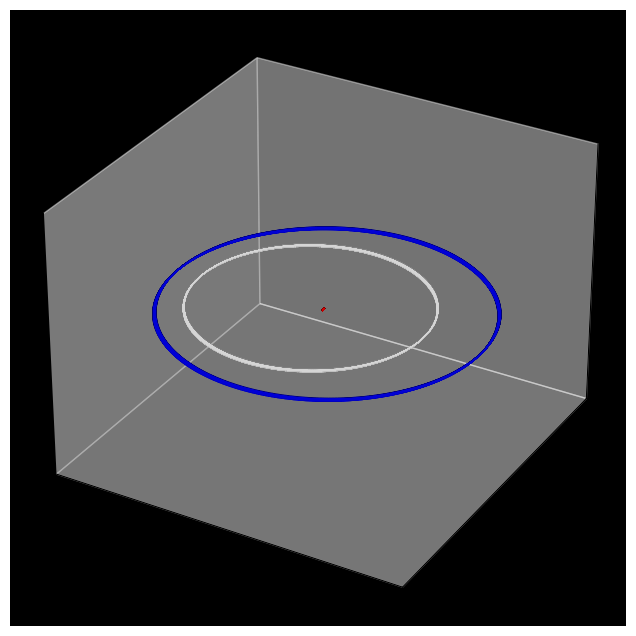

In [21]:
G = 6.67430e-11
m0 = np.array([1.9891e30, 3.285e23, 4.867e24]) #sun, mercury, venus

r0 = np.array([[0, 0 , 0  ],
               [69.818  ,0 ,0  ],
               [108.941 ,0  ,0  ]])*1e9

v0 = np.array([[0, 0, 0],
               [0 , 46, 0],
               [0 , 34.5, 0]])*1000
t0 = 0
tf = 3.1536e10
h = 86400

# Run this line to get the actual data, it takes very long to run and the data is stored seperately
#r1,r2,r3 = rk4(func, r0, v0, m0, t0, tf, h, plot=True)

r1 = np.load('sun_pos.npy')
r2 = np.load('merc_pos.npy')
r3 = np.load('venus_pos.npy')

plot_path(r1,r2,r3)

In [22]:
m1 = np.argmin(np.sqrt(np.sum(r2[0:365]**2,axis=1)))
m2 = np.argmin(np.sqrt(np.sum(r2[365000-366:365000-1]**2,axis=1)))

print('{}, {}'.format(r2[0:365][m1],r2[365000-366:365000-1][m2]))

a = r2[0:365][m1]
b = np.array([0, 0, 0])
c = r2[365000-366:365000-1][m2]

ba = a - b
bc = c - b

cosine_angle = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc))
angle = np.arccos(cosine_angle)

print(np.degrees(angle))

[6.9818e+10 0.0000e+00 0.0000e+00], [ 6.67469317e+10 -1.93803955e+10  0.00000000e+00]
16.190990673087008


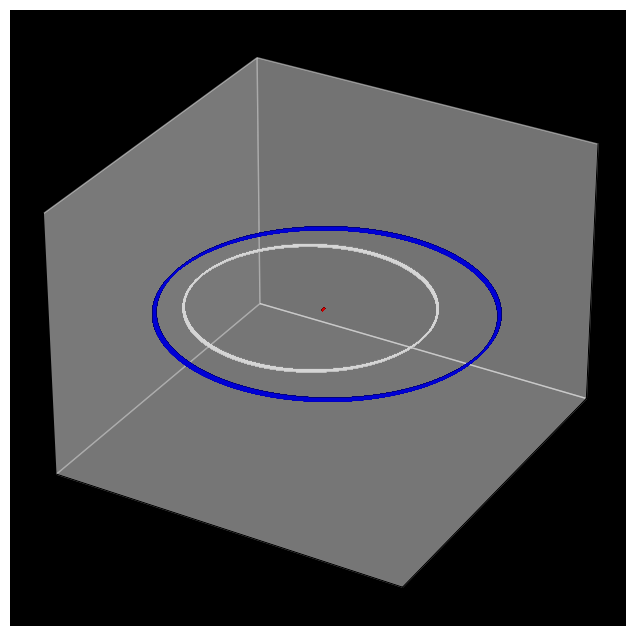

In [23]:
G = 6.67430e-11
m0 = np.array([1.9891e30, 3.285e23, 4.867e24]) #sun, mercury, venus

r0 = np.array([[0, 0 , 0  ],
               [69.818  ,0 ,0  ],
               [108.941 ,0  ,0  ]])*1e9

v0 = np.array([[0, 0, 0],
               [0 , 46, 0],
               [0 , 34.5, 0]])*1000
t0 = 0
tf = 3.1536e10
h = 8640

# Run this line to get the actual data, it takes very long to run and the data is stored seperately
#r1,r2,r3 = rk4(func, r0, v0, m0, t0, tf, h, plot=True)

r1 = np.load('sun_pos_1.npy')
r2 = np.load('merc_pos_1.npy')
r3 = np.load('venus_pos_1.npy')

plot_path(r1,r2,r3)

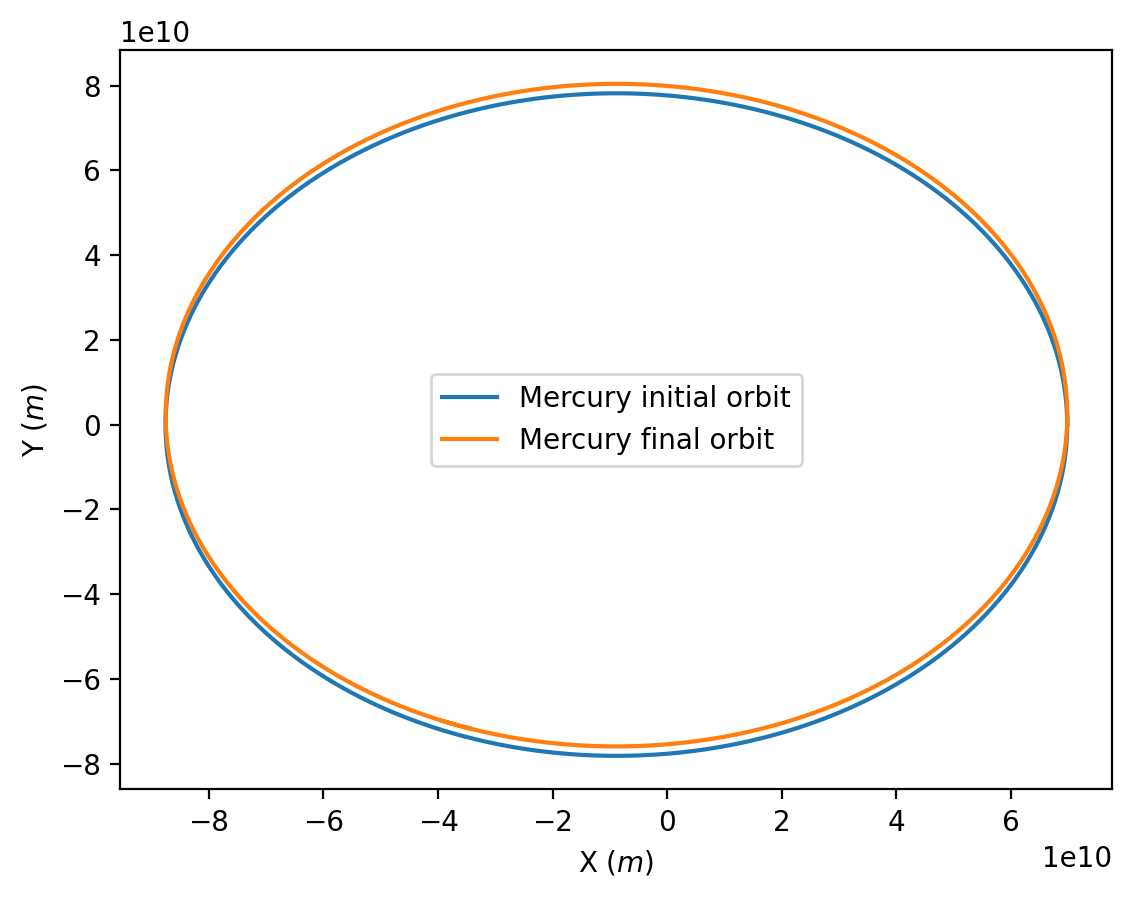

In [24]:
plt.figure(dpi=200)
plt.plot(r2[0:1400,0],r2[0:1400,1],label='Mercury initial orbit')
plt.plot(r2[3650000-1411:3650000-1,0],r2[3650000-1411:3650000-1,1],label='Mercury final orbit')
plt.xlabel(r'X $(m)$')
plt.ylabel(r'Y $(m)$')
plt.legend()

In [18]:
m1 = np.argmin(np.sqrt(np.sum(r2[0:1400]**2,axis=1)))
m2 = np.argmin(np.sqrt(np.sum(r2[3650000-1411:3650000-1]**2,axis=1)))

print('{}, {}'.format(r2[0:1400][m1],r2[3650000-1411:3650000-1][m2]))

a = r2[0:1400][m1]
b = np.array([0, 0, 0])
c = r2[3650000-1411:3650000-1][m2]

ba = a - b
bc = c - b

cosine_angle = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc))
angle = np.arccos(cosine_angle)

print(np.degrees(angle))

[6.9818e+10 0.0000e+00 0.0000e+00], [ 6.67836463e+10 -1.92739047e+10  0.00000000e+00]
16.09825425781024


Save the data in .npy files to save on runtime

In [19]:
np.save('sun_pos_1.npy',r1)
np.save('merc_pos_1.npy',r2)
np.save('venus_pos_1.npy',r3)

The angle between the new orbit and the initial orbit after 1000 years is expected to be 15.43611 degrees, the calculated value was found to be 16.098 with step size of one tenth of a day and 16.191 with stepsize of a day, this is close to the expected answer but is still slightly off, this could be due to a number of reasons, the initial assumption of the orbit positions might be wrong. The most likely issue is the the method itself not being energy conserving. The step sizes do not seem like they would fix the issue as even after reducing the step size by  an order of 10, there was only a minimal improvement. A higher order velocity verlet-like method would provide better results. But this nonetheless is a good demonstration on the effect of Venus's mass on the orbit of Mercury.

## Discussions
Above we demonstrated the use of numerical methods to simulate the motion of 3 bodies under gravitational effects. We find that methods that conserve energy are better than those that do not, and higher order methods also perform better at simulating orbits.

We demonstrated the unstable and chaotic nature of the 3 body problem and more generally the N body problem. Small initial changes can lead to vastly different orbits, this is exacerbated by the fact that collision physics are not modelled and acceleration diverges when particles get very close to eachother.

Stable solutions for the 3 body problem were also demonstrated.

One of the original motivations of the project was to use general relativity to model orbital paths (specifically Mercury's precessing orbit), but that task was too big for the scope of the project along with the difference general relativity fixes in mercuries orbit. Mercury experiences an difference of 5600 arcseconds every 100 Earth years, whereas Newtons law of gravitation predicts a difference of 5557 arcseconds $[5]$. The 47 arcsecond difference was not significant enough to demonstrate and hence the scope was lowered to Newtonian gravity

## References

1. [Solving the Three Body Problem With Python](https://rjallain.medium.com/solving-the-three-body-problem-with-python-2557593115c3)
2. [The three body problem](https://blbadger.github.io/3-body-problem.html)
3. [A remarkable periodic solution of the three-body problem in the case of equal masses](https://arxiv.org/pdf/math/0011268)
4. [The 1223 new periodic orbits of planar three-body problem with unequal mass and zero angular momentum](https://arxiv.org/pdf/1709.04775)
5. [Precession of the perihelion of Mercury](https://aether.lbl.gov/www/classes/p10/gr/PrecessionperihelionMercury.htm)